# BDA500 Project 1 Regression: Predicting Student Math Scores

**Group:** 3
**Team members:** Lionael Surya, Chaehoon Shin, Margil Parekh
**Dataset:** Students Performance in Exams (Kaggle, spscientist)
**Due:** October 14, 2026, 11:59 PM ET

| Member | Sections |
|---|---|
| Lionael Surya | 0 Setup, 1 Problem Framing, 2.1 Load and Inspect, 2.2 Column Roles and Cleaning, 6.1 Configuration Counts, 6.2 Cross-Validated Regression Results |
| Chaehoon Shin | 3.1 Histograms and Boxplots, 3.2 Correlations, 3.3 Possible Cluster Structure, 6.3 Regression Comparison and Selection |
| Margil Parekh | 5 Preprocessing, 6.4 Final Untouched Test Evaluation, 6.5 Actual-vs-Predicted, Residuals and Large Errors |

## 0. Setup

**Question:** Which libraries, paths, target, identifiers, dates, leakage columns, and random settings are required?

In [1]:
# Contributor: Lionael Surya - Section 0 Setup
import warnings, json
# %pip install plotly seaborn joblib -q
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

np.random.seed(42)

# column roles (see 2.2)
target = "math score"
num_cols = ["reading score", "writing score"]
cat_cols = ["gender", "race/ethnicity", "parental level of education",
            "lunch", "test preparation course"]
id_cols, date_cols, leakage_cols = [], [], []   # none in this dataset

print("Libraries loaded")

Libraries loaded


## 1. Problem Framing

**Question:** What continuous value will be predicted in supervised learning? What column values will be combined to form a text in unsupervised learning?

**Supervised question:** Given a student's reading and writing scores, their background, and whether they finished the test-prep course, what math score (0–100) will they get?

| Item | Definition |
|---|---|
| **Target (y)** | `math score`, continuous from 0 to 100 |
| **Features (X)** | `reading score`, `writing score` (numeric); `gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course` (categorical) |
| **Unit of analysis** | One student |
| **Data source** | [Students Performance in Exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams), Kaggle (spscientist), 1,000 students |
| **Intended users** | School counsellors and academic-support staff |
| **Clustering columns (unsupervised)** | `reading score`, `writing score`, `math score`, grouping students by their overall score profile |

**Why it's useful.** Schools often test reading and writing before math, or on a separate day. If we can estimate the math score from those earlier results, a counsellor can flag the students likely to land under 50 and book them into tutoring before the math exam instead of after it. Test prep is also one of the few inputs a school actually controls, so knowing how much it's worth could feed straight into a decision about funding more prep seats.

**Risks and limitations.** We see four:
- Gender, race/ethnicity and lunch (a stand-in for household income) are sensitive. The model should only point extra help toward students; nobody should lose a placement because of a prediction.
- Test prep might not cause anything, since the students who sign up may just be more motivated.
- The early-warning idea assumes reading and writing results arrive before math. If all three tests happen at one sitting, the model still predicts well but it's much less useful.
- At 1,000 rows we fall short of the preferred 5,000–10,000. It's the full public release, so we didn't sample anything, but we don't know which school or year it came from and the results may not carry over elsewhere.

In [2]:
# Contributor: Lionael Surya - Section 1 Problem Framing
y = "math score"
clustering_cols = [
    "reading score",
    "writing score",
    "math score",
]

In [3]:
# Contributor: Lionael Surya - Section 1 target overview
df_raw = pd.read_csv("StudentsPerformance.csv")
print(f"Target: '{target}'  |  n = {df_raw[target].size}")
df_raw[target].describe().round(2)

Target: 'math score'  |  n = 1000


count    1000.00
mean       66.09
std        15.16
min         0.00
25%        57.00
50%        66.00
75%        77.00
max       100.00
Name: math score, dtype: float64

## 2.1 Load and Inspect

**Question:** What are the head, shape, structure, data types, summary statistics, and missing-value counts?

In [4]:
# Contributor: Lionael Surya - Section 2.1 Load and Inspect
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:
print("Data types:")
print(df.dtypes.to_string())
print("\nNumeric summary:")
display(df.describe().T.round(2))
print("Categorical summary:")
display(df.describe(include="object").T)

Data types:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.09,15.16,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.17,14.60,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.05,15.20,10.0,57.75,69.0,79.0,100.0


Categorical summary:


,count,unique,top,freq
gender,1000,2,female,518
race/ethnicity,1000,5,group C,319
parental level of education,1000,6,some college,226
lunch,1000,2,standard,645
test preparation course,1000,2,none,642


In [7]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


**Findings.** The data has 1,000 rows and 8 columns: five text categories and three integer scores between 0 and 100. Not a single value is missing, so there's nothing to impute, though we'll leave a `SimpleImputer` in the pipeline in case future data arrives with gaps.

Math averages 66.1, a few points under reading (69.2) and writing (68.1), and it's the only subject where someone scored 0. All three have a standard deviation close to 15.

## 2.2 Column Roles and Cleaning

**Question:** Which columns are numeric, categorical, identifiers, dates, target, or leakage, and how are duplicates/removals handled?

In [8]:
# Contributor: Lionael Surya - Section 2.2 Column Roles
# decide the role of each column, checking the rules one by one
def get_role(col):
    if col == target:
        return "Target"
    elif col in id_cols:
        return "Identifier"
    elif col in date_cols:
        return "Date"
    elif col in leakage_cols:
        return "Leakage"
    elif col in num_cols:
        return "Numeric"
    else:
        return "Categorical"

roles = pd.DataFrame({"Column": df.columns, "Dtype": df.dtypes.astype(str)})
roles["Role"] = roles["Column"].map(get_role)
roles

,Column,Dtype,Role
gender,gender,object,Categorical
race/ethnicity,race/ethnicity,object,Categorical
parental level of education,parental level of education,object,Categorical
lunch,lunch,object,Categorical
test preparation course,test preparation course,object,Categorical
math score,math score,int64,Target
reading score,reading score,int64,Numeric
writing score,writing score,int64,Numeric


In [9]:
for c in cat_cols:
    print(df[c].value_counts(), "\n")

gender
female    518
male      482
Name: count, dtype: int64 

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64 

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64 

lunch
standard        645
free/reduced    355
Name: count, dtype: int64 

test preparation course
none         642
completed    358
Name: count, dtype: int64 



In [10]:
# Duplicates
print("Duplicates:", df.duplicated().sum())
before = len(df); df = df.drop_duplicates().copy()
removal_log = pd.DataFrame([{"Action": "Drop exact duplicates", "Count": before - len(df), "Reason": "Exact duplicate records"}])
display(removal_log)

# Very low math scores (kept, checked again in 6.5)
df[df[target] < 20]

Duplicates: 0


,Action,Count,Reason
0,Drop exact duplicates,0,Exact duplicate records


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
787,female,group B,some college,standard,none,19,38,32
980,female,group B,high school,free/reduced,none,8,24,23


**Column roles.** `math score` is the target. `reading score` and `writing score` are numeric, and the other five columns are categorical. The data has no ID or date column, so `id_cols` and `date_cols` stay empty.

**Leakage.** A total or average of all three scores would leak the target because it contains the math score, so we don't make one. Reading and writing are fair to use as long as students take those tests before math, or on a different day.

**Cleaning.** We didn't remove anything: the removal log shows 0 duplicate rows, and the summary table in 2.1 shows every score sits between 0 and 100.

The four students under 20 in math look real, not like typos. The one with 0 in math also got 17 in reading and 10 in writing, and a typo wouldn't hit all three subjects, so we keep them and look at them again in 6.5.

**Encoding.** We one-hot encode all five categorical columns. Parental education has an order, but the gaps between levels aren't equal (is "some college" above or below an associate's degree?), so giving it ordinal numbers like 1 to 6 would be guessing.

## 3.1 Histograms and Boxplots

**Question:** What do important numeric distributions and boxplots reveal about spread, skewness, and outliers?

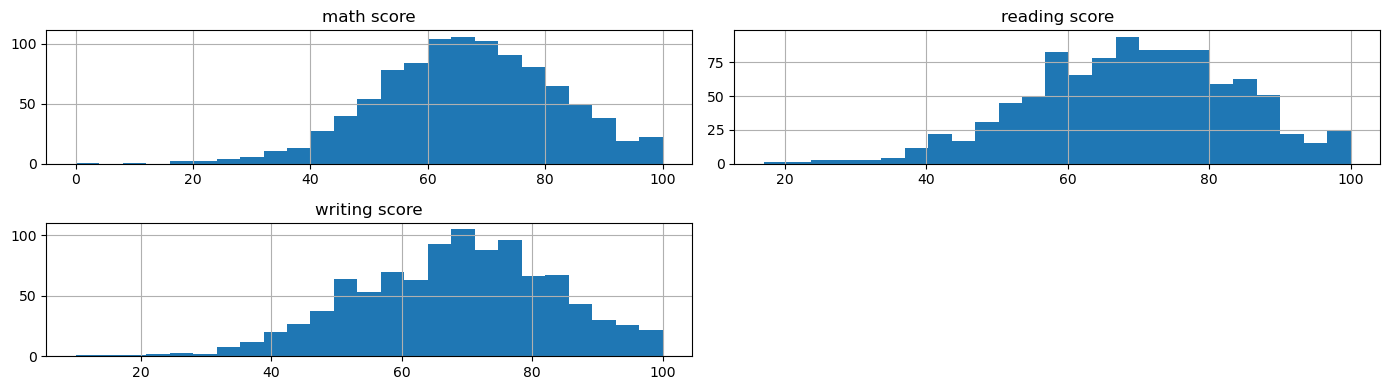

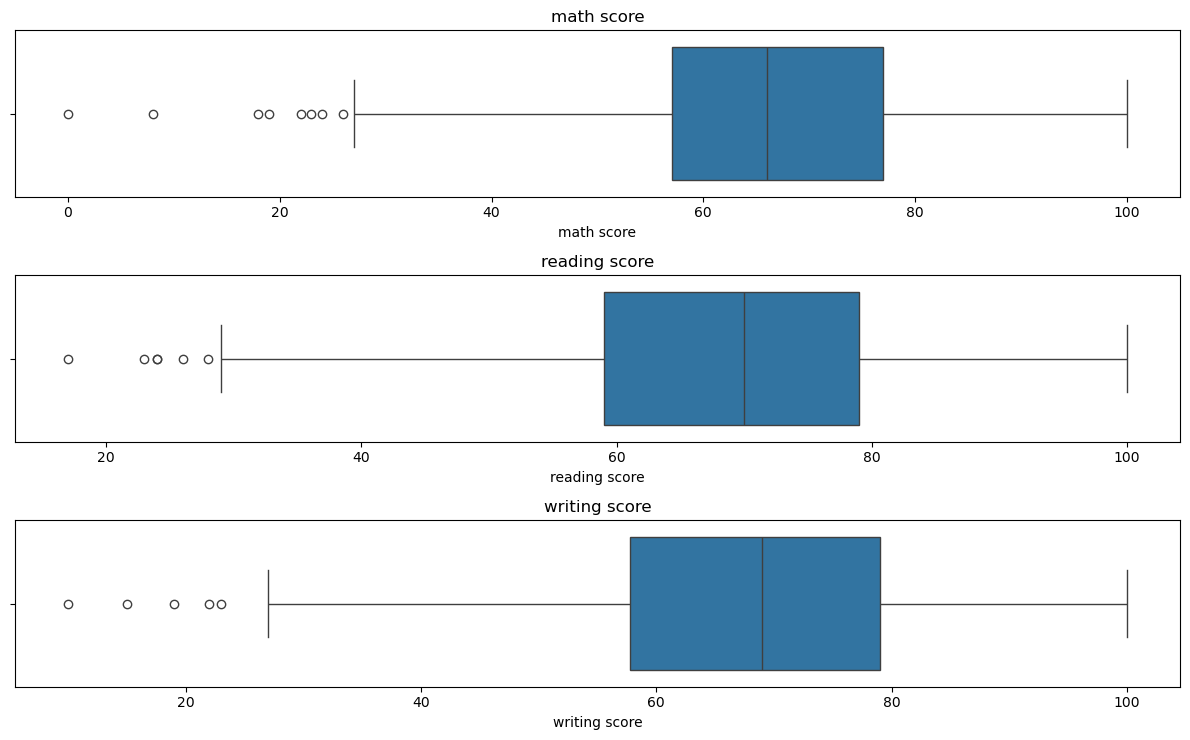

In [11]:
# Contributor: Chaehoon Shin - Section 3.1 Distributions
scores = [target] + num_cols   # math, reading, writing

# histograms: the shape of each score
df[scores].hist(figsize=(14, 4), bins=25)
plt.tight_layout()
plt.show()

# boxplots: dots past the whiskers are possible outliers
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5))
for ax, col in zip(axes, scores):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [12]:
# mean vs median: if the mean is lower, the scores lean left
print(df[scores].agg(["mean", "median"]).round(1), "\n")

# outliers: more than 3 standard deviations from the mean (rule from Lab 1)
for col in scores:
    mean_s = df[col].mean()
    std_s = df[col].std()
    lower_bound = mean_s - 3 * std_s
    upper_bound = mean_s + 3 * std_s
    out_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    print(col)
    print("  bounds:", round(lower_bound, 1), "to", round(upper_bound, 1))
    print("  outliers:", out_mask.sum(), "->", sorted(df.loc[out_mask, col].values))
    print("  students who scored 100:", (df[col] == 100).sum())

        math score  reading score  writing score
mean          66.1           69.2           68.1
median        66.0           70.0           69.0 

math score
  bounds: 20.6 to 111.6
  outliers: 4 -> [0, 8, 18, 19]
  students who scored 100: 7
reading score
  bounds: 25.4 to 113.0
  outliers: 4 -> [17, 23, 24, 24]
  students who scored 100: 17
writing score
  bounds: 22.5 to 113.6
  outliers: 4 -> [10, 15, 19, 22]
  students who scored 100: 14


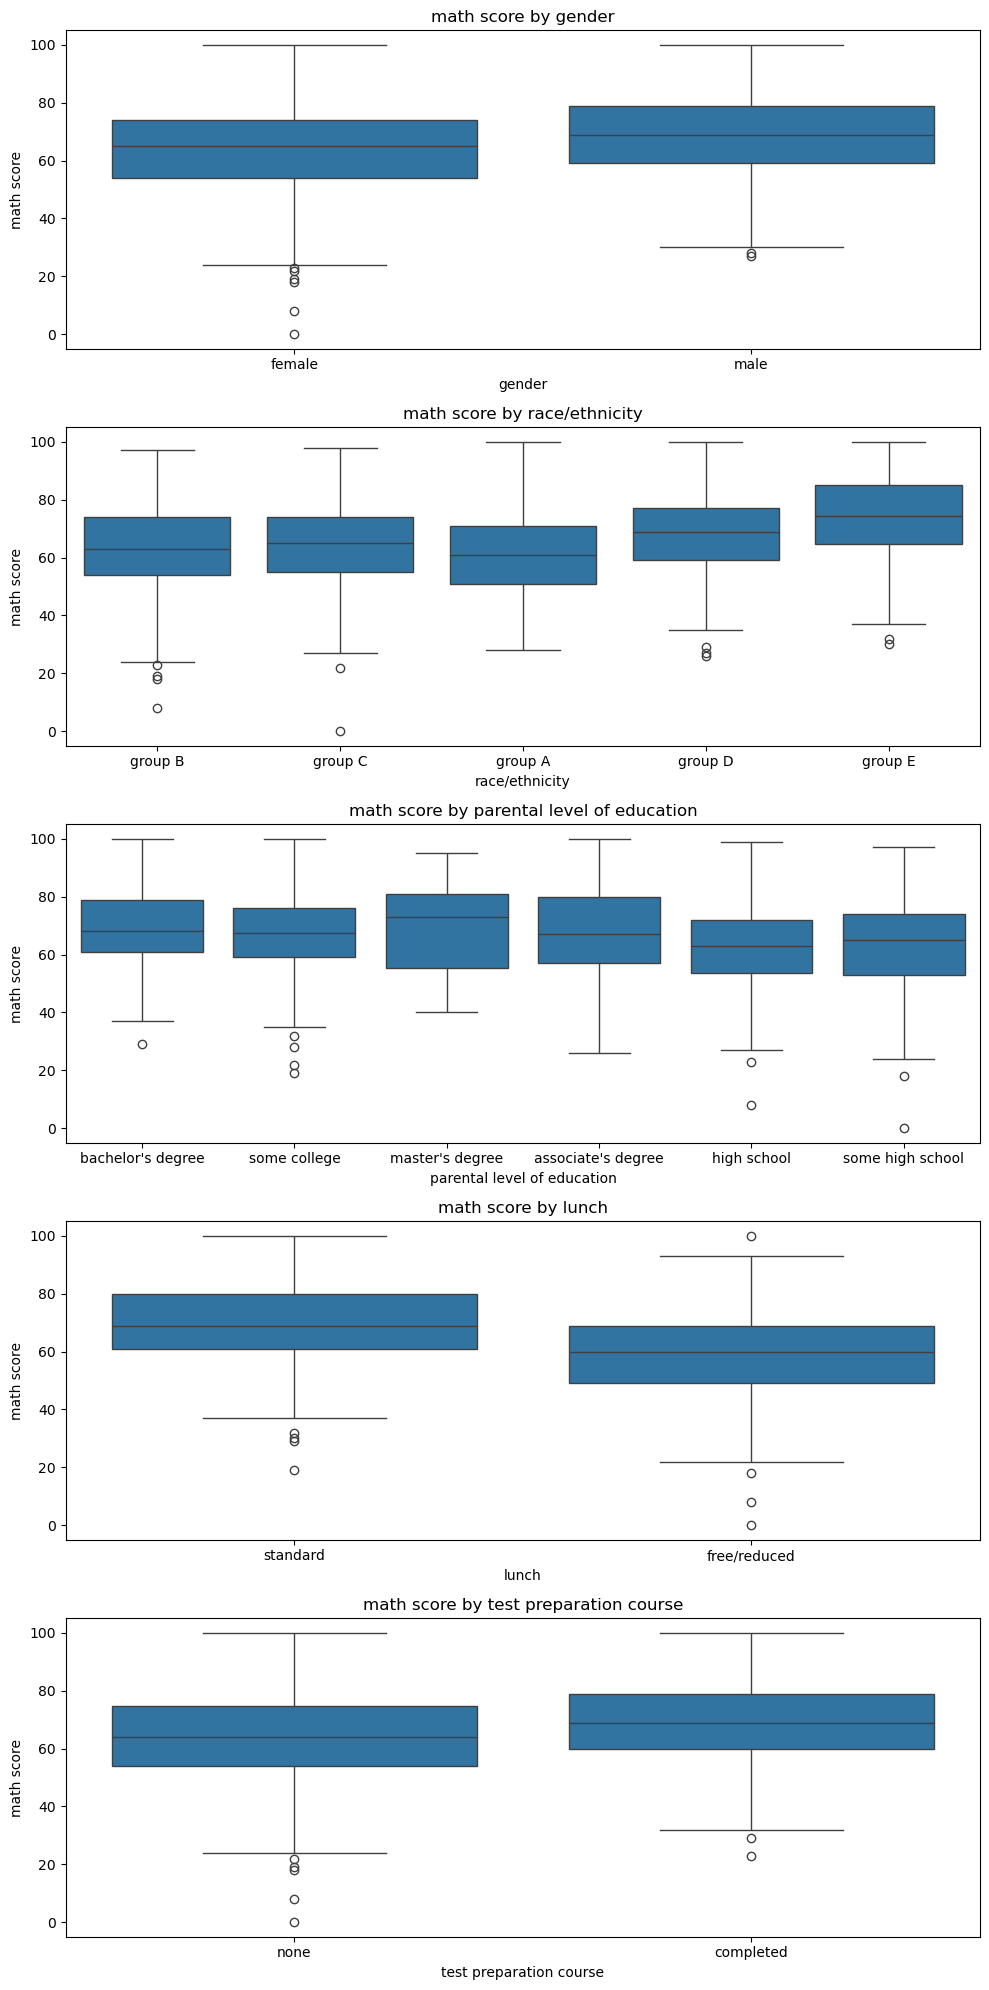

In [13]:
# math score for each group of every categorical column
fig, axes = plt.subplots(5, 1, figsize=(10, 20))
for ax, col in zip(axes, cat_cols):
    sns.boxplot(data=df, x=col, y=target, ax=ax)
    ax.set_title(f"{target} by {col}")
plt.tight_layout()
plt.show()

**Findings:**

**Shape:** All three scores lean a little to the left: the mean is slightly lower than the median (math 66.1 vs 66, reading 69.2 vs 70, writing 68.1 vs 69), because a few very weak students pull the average down. The lean is small, so we don't transform the target.

**Outliers:** We used the rule from Lab 1, where anything more than 3 standard deviations from the mean counts as an outlier. Each subject has 4, and all of them are at the low end:
- math: 0, 8, 18, 19
- reading: 17, 23, 24, 24
- writing: 10, 15, 19, 22

There are no high outliers, because the upper bounds (111 to 114) are above the top possible score of 100. Some students do hit 100: 7 in math, 17 in reading and 14 in writing.

**Spread.** All three scores have a standard deviation of about 15, so they're already on a similar scale. We still standardise them in Section 5 because Ridge needs it.

**Categories** (last set of boxplots). Standard-lunch students score about 11 points higher in math than free/reduced-lunch students, group E is 12 points above group A, finishing test prep adds 5.6, and males score 5.1 higher. Parental education has the weakest pattern and isn't even in order: "high school" (62.1) is the lowest, below "some high school" (63.5).

## 3.2 Correlations and Target Relationships

**Question:** Which numeric variables correlate, and how do at least two important predictors relate to the target?

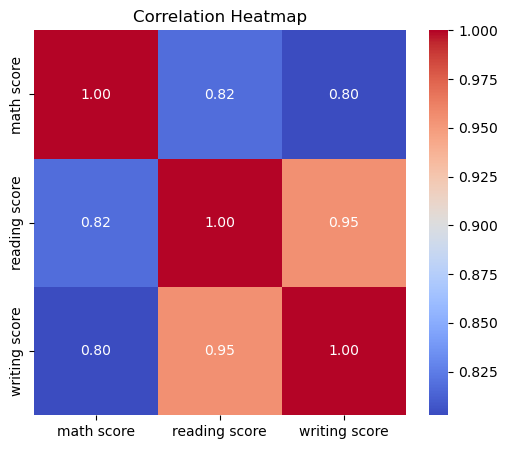

In [14]:
# Contributor: Chaehoon Shin - Section 3.2 Correlations
corr = df[scores].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap"); plt.show()

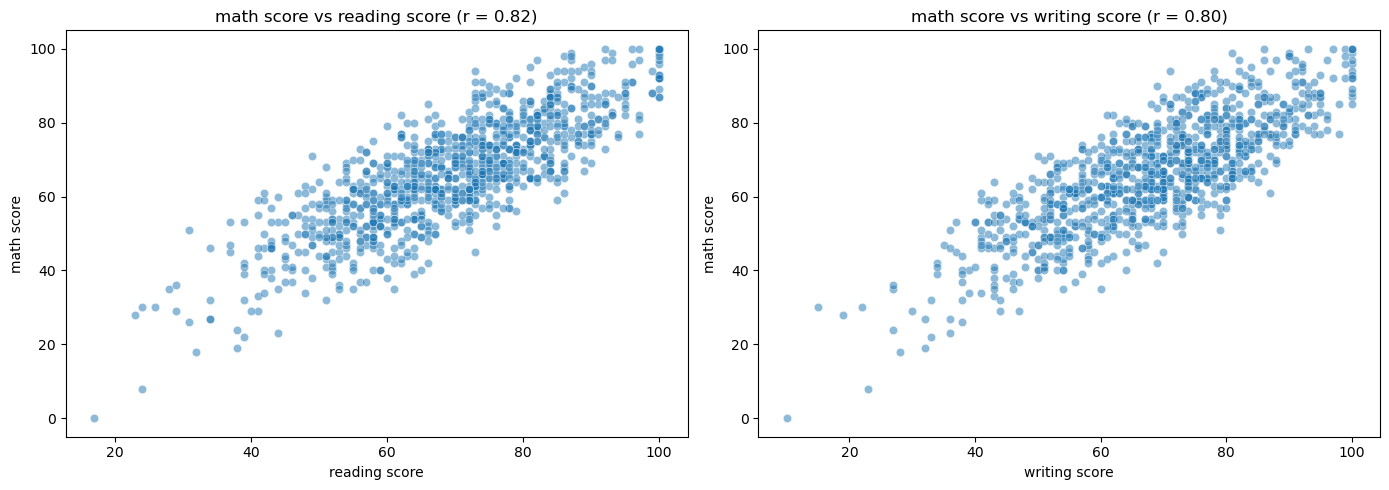

In [15]:
# Predictor vs target: reading and writing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, num_cols):
    sns.scatterplot(data=df, x=col, y=target, alpha=0.5, ax=ax)
    ax.set_title(f"{target} vs {col} (r = {df[col].corr(df[target]):.2f})")
plt.tight_layout(); plt.show()

,feature,max_gap_points
1,race/ethnicity,12.2
3,lunch,11.1
2,parental level of education,7.6
4,test preparation course,5.6
0,gender,5.1


lunch         test preparation course
free/reduced  completed                  63.0
              none                       56.5
standard      completed                  73.5
              none                       68.1
Name: math score, dtype: float64

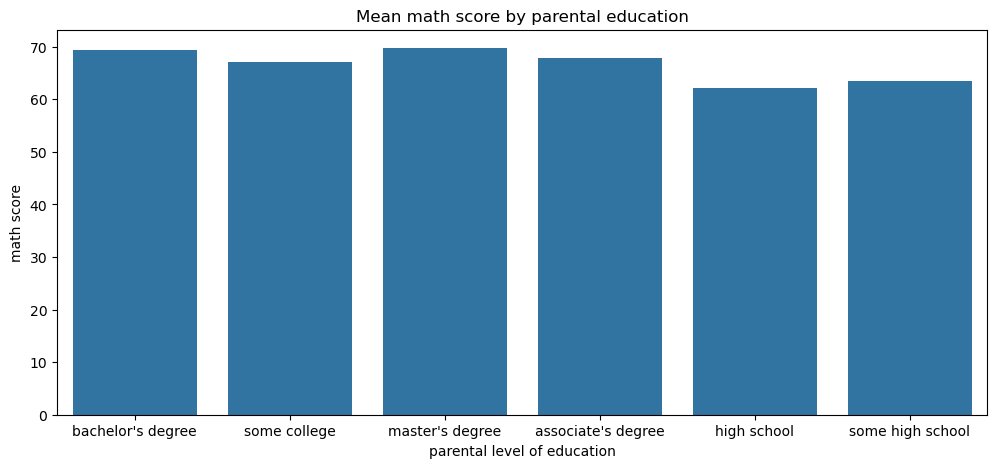

parental level of education
high school           62.1
some high school      63.5
some college          67.1
associate's degree    67.9
bachelor's degree     69.4
master's degree       69.7
Name: math score, dtype: float64

In [16]:
# Mean math score and gap (best level minus worst level) per category
rows = []
for col in cat_cols:
    means = df.groupby(col)[target].mean()
    rows.append({"feature": col, "max_gap_points": round(means.max() - means.min(), 1)})
display(pd.DataFrame(rows).sort_values("max_gap_points", ascending=False))

# Lunch and test prep together
display(df.groupby(["lunch", "test preparation course"])[target].mean().round(1))

plt.figure(figsize=(12, 5))
sns.barplot(data=df, x="parental level of education", y=target, errorbar=None)
plt.title("Mean math score by parental education"); plt.show()
display(df.groupby("parental level of education")[target].mean().round(1).sort_values())

**Findings.** Reading (r = 0.82) and writing (r = 0.80) both track math closely, and the scatterplots show a straight-line trend with fairly even spread, which suits Linear and Ridge regression.

The catch? Reading and writing correlate with each other at 0.95, so they're close to redundant. Plain linear regression can split the credit between them in unstable ways, and Ridge's L2 penalty exists for exactly this situation; it's the main reason Ridge belongs in the Section 6 comparison.

Ranked by the gap in mean math score between their best and worst level, the categories go race/ethnicity (12.2 points), lunch (11.1), parental education (7.6), test prep (5.6) and gender (5.1). Lunch and test prep stack on top of each other: standard lunch plus finished prep averages 73.5, while free/reduced lunch with no prep averages 56.5.

## 3.3 Possible Cluster Structure

**Question:** Does a scatterplot of two important features reveal possible grouping, overlap, or outliers?

        math score  reading score  writing score
gender                                          
female        63.6           72.6           72.5
male          68.7           65.5           63.3


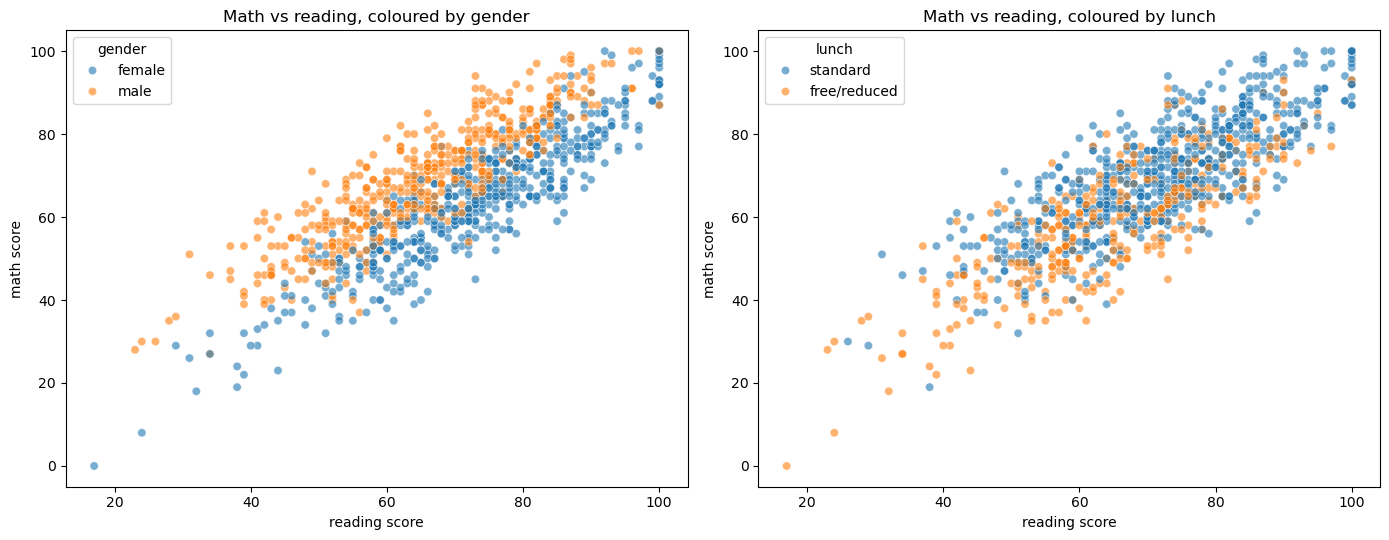

reading score  gender
(0, 50]        female    33.4
               male      49.2
(50, 70]       female    53.7
               male      63.8
(70, 85]       female    68.0
               male      79.6
(85, 100]      female    82.6
               male      92.9
Name: math score, dtype: float64

In [17]:
# Contributor: Chaehoon Shin - Section 3.3 Grouping
print(df.groupby("gender")[scores].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x="reading score", y=target, hue="gender", alpha=0.6, ax=axes[0])
axes[0].set_title("Math vs reading, coloured by gender")
sns.scatterplot(data=df, x="reading score", y=target, hue="lunch", alpha=0.6, ax=axes[1])
axes[1].set_title("Math vs reading, coloured by lunch")
plt.tight_layout(); plt.show()

# Gender gap in math at similar reading scores
reading_band = pd.cut(df["reading score"], bins=[0, 50, 70, 85, 100])
df.groupby([reading_band, "gender"])[target].mean().round(1)

**Findings.** Gender splits the scatter into two bands. Females score higher in reading (72.6 vs 65.5) and writing (72.5 vs 63.3) but lower in math (63.6 vs 68.7), so at any given reading score a male student tends to score well above a female student in math. The table under the plots puts numbers on it: among students reading 50 or below, males average 15.8 points more in math, and in every higher reading band the gap sits between 10 and 12 points. The gap is widest among the weakest readers, which hints at a gender × reading interaction, though only the lowest band stands out. It also explains why gender looks weak on its own (a 5-point gap) yet carries real information once reading is in the model, so it stays.

Lunch doesn't separate anything; free/reduced-lunch students drift toward the lower left but show up across the whole range.

We don't see natural clusters. The students form one long cloud along the reading–math diagonal, and the four who scored under 20 in math sit at its bottom-left end, low in every subject, following the trend instead of breaking it. Expect them to produce some of the largest residuals anyway.

### Summary for modelling (handoff to Sections 5–6)
| Decision | Choice | Reason |
|---|---|---|
| Missing values | None present; optional `SimpleImputer` safeguard | 0 missing in all columns |
| Rows removed | None | 0 duplicates; outliers are genuine |
| Numeric preprocessing | Median `SimpleImputer` → `StandardScaler` on reading, writing | Ridge needs it; puts features on a common scale |
| Categorical encoding | Most-frequent `SimpleImputer` → `OneHotEncoder(handle_unknown="ignore")` on all 5 | Nominal categories; parental-education gaps aren't equal |
| Key risk | Reading–writing collinearity (r = 0.95) | Favours Ridge; read linear coefficients with care |

## 5. Preprocessing

**Question:** How are missing values, categorical encoding, and numeric scaling performed ?

In [18]:
# Contributor: Margil Parekh - Section 5 Preprocessing (Prepare Feature)

# Drop ID, date and leakage columns (all three lists are empty here, so nothing gets removed)
df_model = df.drop(columns=id_cols + date_cols + leakage_cols, errors="ignore").copy()

# X = the 7 input columns the model learns from, y = the math score it predicts
X = df_model.drop(columns=target)
y = df_model[target]

# Split the input columns by type: numbers vs text categories
num_features = X.select_dtypes(include=np.number).columns.tolist()   # reading score, writing score
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()   # gender, race/ethnicity, parental education, lunch, test prep

# Numeric steps: fill any blank with the median, then scale to mean 0 and standard deviation 1
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])

# Categorical steps: fill any blank with the most common level, then one-hot encode
# (one 0/1 column per level; a level the model never saw in training becomes all zeros instead of an error)
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

# Combine numeric and categorical preprocessing: each column goes to the right pipe.
# Nothing is fitted yet; it gets fitted later, on training data only, inside each model's Pipeline (6.2)
preprocessor = ColumnTransformer([("num", num_pipe, num_features), ("cat", cat_pipe, cat_features)])

print("Numeric features:", num_features)
print("Categorical features:", cat_features)
# 2 numeric columns + one column per category level (2 + 5 + 6 + 2 + 2 = 17) = 19
print("Columns after encoding:", len(num_features) + sum(len(X[c].unique()) for c in cat_features))

Numeric features: ['reading score', 'writing score']
Categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
Columns after encoding: 19


**Answer.** Both pipelines sit inside one `ColumnTransformer`, and every model refits it on each training fold, so test rows never touch the imputer, scaler or encoder.

- **Missing values:** median for the two scores and the most frequent level for the categories. The data has no gaps, so these only matter if future students arrive with blanks.
- **Encoding:** one-hot for all five categorical columns (17 dummy columns); `handle_unknown="ignore"` turns a level the model never saw into all zeros instead of an error.
- **Scaling:** `StandardScaler` on reading and writing, because Ridge's penalty assumes every coefficient is on the same scale.

That gives 19 columns going into each model.

## 6.1 Regression Configuration Counts

**Question:** How many configurations result from test sizes 10%, 25%, 30%; random states 0 and 42; five-fold CV; alpha 1; and polynomial degrees  3?

In [19]:
# Contributor: Lionael Surya - Section 6.1 Configuration Counts

# Settings from the project brief
test_sizes = [0.10, 0.25, 0.30]   # share of students held out as the test set
random_states = [0, 42]           # seeds that decide which students land in train vs test
cv_folds = 5                      # 5-fold cross-validation on the training part
alpha = 1.0                       # Ridge penalty strength (fixed at 1.0 by the brief)
degrees = [3]                     # polynomial degree (fixed at 3 by the brief)

# Runs per model: 3 test sizes x 2 random states x 1 CV setting x 1 fixed alpha/degree = 6
per_model = len(test_sizes) * len(random_states) * 1
counts = {"Linear Regression": per_model,
          "Ridge Regression": per_model * 1,                  # only one alpha value
          "Polynomial Regression": per_model * len(degrees)}  # only one degree value
display(pd.Series(counts, name="Configurations").to_frame())
print("Total configurations:", sum(counts.values()))   # 6 per model x 3 models = 18

# List every configuration we run (matches the tables in the project brief)
configs = []
for name in ["Linear Regression", "Ridge Regression", "Polynomial Regression"]:
    for ts in test_sizes:
        for rs in random_states:
            # alpha only applies to Ridge and degree only to Polynomial; None = not used by that model
            configs.append({"Model": name, "Test size": f"{int(ts * 100)}%", "Random state": rs, "CV folds": cv_folds,
                            "Alpha": alpha if name == "Ridge Regression" else None,
                            "Degree": degrees[0] if name == "Polynomial Regression" else None})
display(pd.DataFrame(configs))

,Configurations
Linear Regression,6
Ridge Regression,6
Polynomial Regression,6


Total configurations: 18


,Model,Test size,Random state,CV folds,Alpha,Degree
0,Linear Regression,10%,0,5,NaN,NaN
1,Linear Regression,10%,42,5,NaN,NaN
2,Linear Regression,25%,0,5,NaN,NaN
3,Linear Regression,25%,42,5,NaN,NaN
4,Linear Regression,30%,0,5,NaN,NaN
5,Linear Regression,30%,42,5,NaN,NaN
6,Ridge Regression,10%,0,5,1.0,NaN
7,Ridge Regression,10%,42,5,1.0,NaN
8,Ridge Regression,25%,0,5,1.0,NaN
9,Ridge Regression,25%,42,5,1.0,NaN


## 6.2 Cross-Validated Regression Results

**Question:** What are mean and standard deviation of CV MAE, RMSE, and R-squared for every required configuration?

In [20]:
# Contributor: Lionael Surya - Section 6.2 Validate Regression Results

# Builds one model as a Pipeline: preprocessing first, then the regression model.
# Because the preprocessor sits inside the Pipeline, it only ever learns from the data the Pipeline is fitted on.
def regression_pipeline(model_name, degree=None, alpha=None):
    steps = [("preprocessor", preprocessor)]                  # step 1: impute, scale, one-hot (Section 5)
    if model_name == "Linear Regression":
        steps.append(("regressor", LinearRegression()))       # plain straight-line fit
    elif model_name == "Ridge Regression":
        steps.append(("regressor", Ridge(alpha=alpha)))       # straight-line fit + penalty on big coefficients
    elif model_name == "Polynomial Regression":
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))  # adds squares, cubes and products of every column
        steps.append(("regressor", LinearRegression()))       # then a straight-line fit on all those new columns
    return Pipeline(steps)

# The three models to compare as (model name, degree, alpha); None = setting not used
model_specs = ([("Linear Regression", None, None), ("Ridge Regression", None, alpha)]
               + [("Polynomial Regression", d, None) for d in degrees])
# Metrics scored on each fold. sklearn reports errors as negatives ("neg_"), so we flip the sign below
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
records = []   # one row of results per (test size, random state, model) goes in here

# Loops over every test size and random state and splits the data each time
for ts in test_sizes:
    for rs in random_states:
        # Hold out the test set (Xhold, yhold) and never use it here; CV runs on the training part only
        Xtr, Xhold, ytr, yhold = train_test_split(X, y, test_size=ts, random_state=rs)
        # Cut the training part into 5 shuffled folds (same seed as the split)
        cv = KFold(n_splits=cv_folds, shuffle=True, random_state=rs)
        for name, d, a in model_specs:
            # Train on 4 folds and score on the 5th, 5 times over; s holds the 5 scores for each metric
            s = cross_validate(regression_pipeline(name, d, a), Xtr, ytr, cv=cv, scoring=scoring)
            # Boil the 5 fold scores down to one row: the mean and standard deviation of each metric
            records.append({
                "Model": name,
                "Feature_Set": str(X.columns.tolist()),               # the 7 input columns
                "CV_or_Split": f"{cv_folds}-fold; test={ts}; state={rs}",  # how this row was produced
                "Best_Params": str({"degree": d, "alpha": a}),        # settings used for this model
                "MAE": -s["test_MAE"].mean(), "MAE_SD": s["test_MAE"].std(),    # negative scores -> positive
                "RMSE": -s["test_RMSE"].mean(), "RMSE_SD": s["test_RMSE"].std(),
                "R2": s["test_R2"].mean(), "R2_SD": s["test_R2"].std(),
                "Test_Size": ts, "Random_State": rs, "Degree": d, "Alpha": a,
                "Notes": "Training-fold metrics only"})               # the test set isn't used yet

# Compile results: 18 rows (3 test sizes x 2 random states x 3 models)
regression_results = pd.DataFrame(records)
# Keep only the 8 columns the brief asks for in the Excel sheet
reg_export = regression_results[["Model", "Feature_Set", "CV_or_Split", "Best_Params", "MAE", "RMSE", "R2", "Notes"]]
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)   # make the folder if it isn't there yet
# Saving it into Excel Workbook
with pd.ExcelWriter(output_dir / "BDA500_Group3_Model_Comparison.xlsx", engine="openpyxl") as w:
    reg_export.to_excel(w, sheet_name="Regression_Results", index=False)
print("Exports saved")

# Full results with standard deviations, sorted by model
display(regression_results.drop(columns=["Feature_Set", "CV_or_Split", "Best_Params", "Notes"])
        .sort_values(["Model", "Test_Size", "Random_State"]).round(3))
# Check: each model should have exactly 6 rows
display(regression_results.groupby("Model").size().to_frame("Rows"))

Exports saved


,Model,MAE,MAE_SD,RMSE,RMSE_SD,R2,R2_SD,Test_Size,Random_State,Degree,Alpha
0,Linear Regression,4.279,0.236,5.349,0.263,0.876,0.007,0.10,0,NaN,NaN
3,Linear Regression,4.339,0.239,5.421,0.258,0.864,0.020,0.10,42,NaN,NaN
6,Linear Regression,4.307,0.253,5.371,0.334,0.874,0.019,0.25,0,NaN,NaN
9,Linear Regression,4.312,0.113,5.389,0.161,0.869,0.009,0.25,42,NaN,NaN
12,Linear Regression,4.356,0.431,5.407,0.453,0.876,0.025,0.30,0,NaN,NaN
15,Linear Regression,4.337,0.218,5.403,0.200,0.866,0.011,0.30,42,NaN,NaN
2,Polynomial Regression,6.571,0.855,9.074,1.935,0.628,0.164,0.10,0,3.0,NaN
5,Polynomial Regression,14.919,17.910,57.358,98.988,-60.088,121.598,0.10,42,3.0,NaN
8,Polynomial Regression,9.796,3.048,20.028,10.519,-1.205,2.094,0.25,0,3.0,NaN
11,Polynomial Regression,19.504,19.897,77.612,97.981,-71.622,124.642,0.25,42,3.0,NaN


,Rows
Model,
Linear Regression,6
Polynomial Regression,6
Ridge Regression,6


## 6.3 Regression Comparison and Selection

**Question:** Which model wins primarily on cross-validated RMSE while considering MAE, R-squared, variability, simplicity, and interpretability?

,MAE,RMSE,RMSE_SD,R2
Model,,,,
Ridge Regression,4.320,5.389,0.278,0.871
Linear Regression,4.322,5.390,0.278,0.871
Polynomial Regression,15.206,51.519,57.465,-39.584


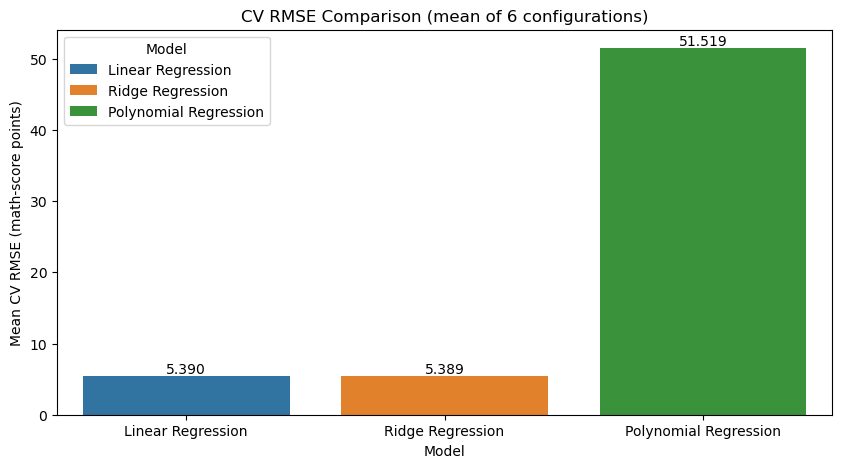

,Selected
Model,Ridge Regression
CV_or_Split,5-fold; test=0.1; state=0
Best_Params,"{'degree': None, 'alpha': 1.0}"
MAE,4.276509
MAE_SD,0.236872
RMSE,5.348225
RMSE_SD,0.263356
R2,0.875998
R2_SD,0.00685
Test_Size,0.1


In [21]:
# Contributor: Chaehoon Shin - Section 6.3 Comparison and Selection

# Comparison table: average each model's 6 rows, best (lowest RMSE) first.
# RMSE_SD = how much the RMSE moved between the 5 folds, on average
model_summary = regression_results.groupby("Model")[["MAE", "RMSE", "RMSE_SD", "R2"]].mean().sort_values("RMSE")
display(model_summary.round(3))

# RMSE bar chart for all three models (each bar = mean of that model's 6 configurations)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=regression_results, x="Model", y="RMSE", hue="Model", errorbar=None, legend=True)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f")   # write the value on top of each bar
plt.title("CV RMSE Comparison (mean of 6 configurations)")
plt.xlabel("Model")
plt.ylabel("Mean CV RMSE (math-score points)")
plt.show()

# Select the configuration with the lowest CV RMSE (the brief's main rule)
best_reg = regression_results.loc[regression_results.RMSE.idxmin()]   # idxmin = row with the smallest RMSE
display(best_reg.drop("Feature_Set").to_frame("Selected"))            # hide the long column list to keep it short

**Selection: Ridge Regression, 10% test set, random state 0.** It has the lowest CV RMSE of all 18 configurations (5.35), and it also has the lowest CV MAE (4.28) and the highest R² (0.876), so every metric points the same way.

Linear Regression is a near tie. Averaged over their six configurations, Ridge and Linear differ by 0.001 RMSE (5.389 vs 5.390), under 1% of the 0.28 fold-to-fold SD, and each Ridge configuration beats its Linear twin by about that sliver. With `alpha = 1` and 700–900 training rows, the penalty barely moves the coefficients.

Polynomial Regression fails badly. Degree 3 on all 19 encoded columns produces 1,539 features, more than the 560–720 rows each CV fold trains on, so plain least squares fits noise: CV RMSE ranges from 9.1 to 103.4, R² falls as low as −95, and the fold SD reaches 112. Section 3.3 pointed to one useful interaction (gender × reading), but it's buried among more than a thousand useless ones.

Ridge and Linear tie on simplicity and interpretability, since both keep one coefficient per input column, read as math-score points. Ridge gets the nod because it wins the primary criterion, and its L2 penalty keeps the reading and writing coefficients steady despite their 0.95 correlation.

## 6.4 Final Untouched Test Evaluation

**Question:** How does the selected model perform when its matching held-out test set is evaluated once?

In [22]:
# Contributor: Margil Parekh - Section 6.4 Test Evaluation

# Read the winner's settings out of best_reg (picked in 6.3)
name = best_reg.Model
ts = float(best_reg.Test_Size)
rs = int(best_reg.Random_State)
# Degree/alpha are NaN (empty) when a model doesn't use them; turn NaN back into None
degree = None if pd.isna(best_reg.Degree) else int(best_reg.Degree)
alpha_sel = None if pd.isna(best_reg.Alpha) else float(best_reg.Alpha)

# Re-create the same split for the winning configuration (10% test, random state = 0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=rs)
# Fit on the training part only (the preprocessor learns its medians, means and categories here)
selected_regression = regression_pipeline(name, degree, alpha_sel).fit(X_train, y_train)
# Predict the untouched test students; this is the only time the test set gets used
y_pred = selected_regression.predict(X_test)

# Score the predictions against the real math scores
final_metrics = pd.DataFrame([{"Model": name, "Test_Size": ts, "Random_State": rs,
                               "MAE": mean_absolute_error(y_test, y_pred),          # average miss, in points
                               "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,   # square root of MSE; punishes big misses more
                               "R2": r2_score(y_test, y_pred)}])                    # share of the score variation explained (1 = perfect)
display(final_metrics.round(3))

,Model,Test_Size,Random_State,MAE,RMSE,R2
0,Ridge Regression,0.1,0,4.589,5.816,0.836


Ridge scored MAE 4.59, RMSE 5.82 and R² 0.836 on the 100 untouched test students. That's 0.47 RMSE worse than its CV estimate of 5.35, and R² drops from 0.876. Part of the gap comes from the small test set, where one student off by 14 points moves RMSE noticeably; part is optimism from picking the best of 18 CV scores. A typical prediction still lands within about 5–6 points on the 0–100 scale.

## 6.5 Actual-vs-Predicted, Residuals, and Large Errors

**Question:** Where does the selected model perform well or poorly, and what explains large errors or outliers?

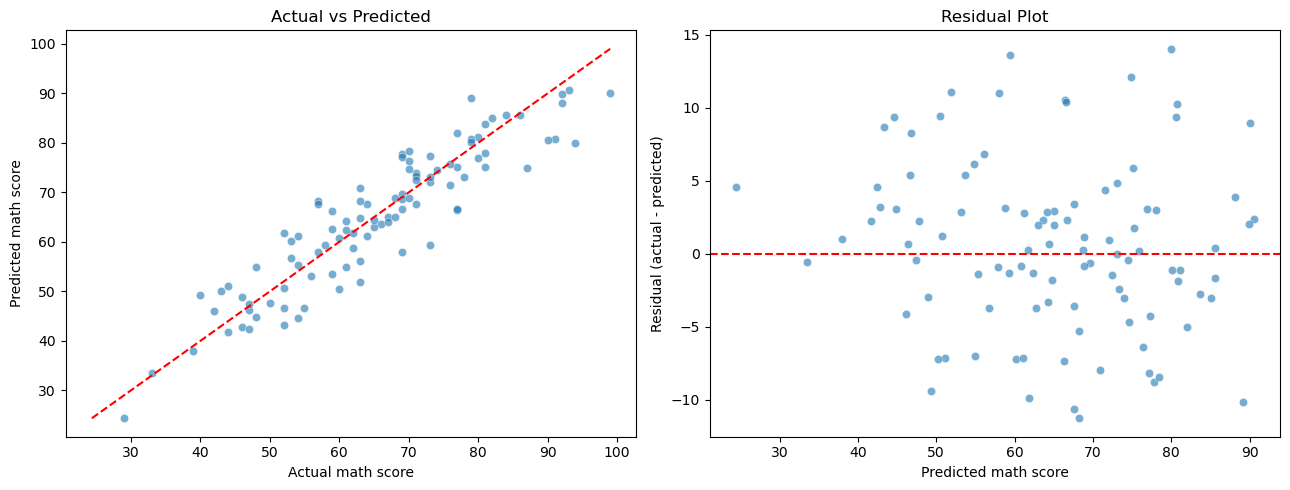

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score,Actual,Predicted,Residual,Absolute_Error
501,female,group B,associate's degree,standard,completed,87,92,94,80.0,14.0,14.0
279,male,group B,bachelor's degree,free/reduced,none,56,57,73,59.4,13.6,13.6
859,male,group C,associate's degree,free/reduced,none,73,72,87,74.9,12.1,12.1
918,female,group C,associate's degree,standard,completed,77,80,57,68.3,-11.3,11.3
568,male,group B,high school,free/reduced,none,48,47,63,51.9,11.1,11.1
366,male,group C,high school,standard,completed,58,53,69,58.0,11.0,11.0
553,male,group D,some college,free/reduced,none,62,64,77,66.4,10.6,10.6
698,female,group D,associate's degree,standard,completed,78,79,57,67.6,-10.6,10.6
693,female,group D,associate's degree,standard,none,77,73,77,66.6,10.4,10.4
784,male,group C,bachelor's degree,standard,completed,81,79,91,80.7,10.3,10.3


Within 5 points: 63 of 100
Errors over 10 points: 11
Mean residual: 0.53
Actual 90+: 7 students, mean residual 7.29 | highest prediction: 90.6 | lowest actual: 29
gender
female   -8.9
male      4.3
dtype: float64


In [23]:
# Contributor: Margil Parekh - Section 6.5 Residual Analysis

# Residual = actual - predicted. Positive means the model guessed too low
residuals = y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))   # two plots side by side

# Plot 1: actual vs predicted. Points on the red dashed line are perfect predictions
sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], alpha=0.6)
lo = min(y_test.min(), y_pred.min())   # the line runs from the lowest score...
hi = max(y_test.max(), y_pred.max())   # ...to the highest
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set(title="Actual vs Predicted", xlabel="Actual math score", ylabel="Predicted math score")

# Plot 2: residuals vs predicted. Points should scatter evenly around the red line at 0
sns.scatterplot(x=y_pred, y=residuals, ax=axes[1], alpha=0.6)
axes[1].axhline(0, color="red", ls="--")
axes[1].set(title="Residual Plot", xlabel="Predicted math score", ylabel="Residual (actual - predicted)")
plt.tight_layout()
plt.show()

# Table of the 10 biggest misses
errors = X_test.copy()                                 # the test students' inputs
errors["Actual"] = y_test
errors["Predicted"] = y_pred.round(1)
errors["Residual"] = residuals.round(1)                # positive = model under-predicted
errors["Absolute_Error"] = np.abs(residuals).round(1)  # size of the miss, ignoring direction
display(errors.nlargest(10, "Absolute_Error"))

# Numbers quoted in the findings below
print("Within 5 points:", (np.abs(residuals) <= 5).sum(), "of", len(residuals))
print("Errors over 10 points:", (np.abs(residuals) > 10).sum())
print("Mean residual:", round(residuals.mean(), 2))   # close to 0 = no overall bias up or down
top = y_test.to_numpy() >= 90                          # True for students who scored 90 or more
print("Actual 90+:", top.sum(), "students, mean residual", round(residuals[top].mean(), 2),
      "| highest prediction:", round(y_pred.max(), 1), "| lowest actual:", y_test.min())
# Typical math score minus literacy average, by gender (whole dataset):
# girls usually score below their reading/writing average in math, boys above it
gap = df[target] - (df["reading score"] + df["writing score"]) / 2
print(gap.groupby(df["gender"]).mean().round(1))

**Findings.** The model does well across the middle of the range. 63 of the 100 test students land within 5 points of their prediction, and the residuals scatter around zero (mean +0.5) with roughly the same spread from a predicted 45 up to 85, so a straight-line model isn't missing an obvious curve.

It's weaker at the top. The seven students who scored 90 or more were under-predicted by 7.3 points on average, and nobody got a prediction above 90.6; the model pulls strong students back toward the mean, and 8 of the 10 largest errors are under-predictions.

The 11 errors bigger than 10 points share one pattern: each student's math score sits unusually far from their reading and writing for their gender. Across the whole dataset girls score about 9 points below their literacy average in math and boys about 4 above it, and the model bakes in roughly that offset through the gender column. Row 279, a boy with a 56.5 literacy average, scored 73 in math, 16.5 above it; rows 918 and 698, two girls averaging 78.5, both scored 57, which is 21.5 below. Row 501 is a girl who scored 94, 4.5 points above her literacy average instead of 9 below, so she's a miss at the top end as well. None of the seven inputs can explain why a student breaks their group's usual gap (math-specific tutoring, study habits or a bad test day might), so more data would shrink these errors more than a different model would.

The four students who scored under 20 in math (Section 2.2) all fell into the training set for this split. The lowest math score in the test set is 29, so they don't appear here.